# 04 – Mô hình dự đoán rời bỏ & giải thích SHAP

Công việc 3.1–3.6: so sánh mô hình, đánh giá out-of-time, chọn ngưỡng, giải thích bằng SHAP.

> **Quyền riêng tư:** `customer_id` được dựng từ số điện thoại khách hàng. Notebook chỉ hiển thị số liệu tổng hợp hoặc mã đã che (`KH_0908***444`). Không in trực tiếp cột `customer_id` / `bill_phone_number` / `bill_full_name`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # bảng màu đã kiểm định CVD
from backend.ml import feature_engineering as fe
from backend.app.core.customer_store import mask_customer_id  # che số điện thoại khi hiển thị

## 1. Kết quả huấn luyện (từ `train_pipeline.py`)
Pipeline đã chạy GridSearchCV 5-fold cho 4 mô hình; ở đây đọc lại `model_metrics.json` và mô hình đã lưu để phân tích sâu hơn (không huấn luyện lại).

In [2]:
import joblib
from backend.app.core.ml_models import load_metrics
from backend.app.core.config import SAVED_MODELS_DIR
m = load_metrics()["churn"]
tbl = pd.DataFrame([{"Mô hình": x["model"], "CV ROC-AUC": x["cv_roc_auc_mean"], **{k: x["test"][k] for k in ["accuracy", "balanced_accuracy", "precision", "recall", "f1_score", "roc_auc", "retained_recall"]}} for x in m["models"]]).set_index("Mô hình")
print("Mô hình phục vụ:", m["best_model"], m["best_model_params"])
print(f"Baseline đoán toàn 'churn': accuracy = {m['majority_baseline_accuracy_test']:.4f}")
tbl.round(4)

Mô hình phục vụ: XGBoost {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 200}
Baseline đoán toàn 'churn': accuracy = 0.9622


,CV ROC-AUC,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc,retained_recall
Mô hình,,,,,,,,
Logistic Regression,0.6594,0.6861,0.5571,0.9682,0.6967,0.8103,0.6180,0.4175
Decision Tree,0.6295,0.6938,0.5937,0.9720,0.7020,0.8152,0.6025,0.4854
Random Forest,0.6555,0.6579,0.5937,0.9726,0.6631,0.7886,0.6118,0.5243
XGBoost,0.6612,0.6685,0.5759,0.9704,0.6761,0.7969,0.6103,0.4757


## 2. Đánh giá lại mô hình đã lưu trên tập kiểm tra out-of-time

In [3]:
from backend.ml.train_advanced import prepare_dataset
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve
data = prepare_dataset()
model = joblib.load(f"{SAVED_MODELS_DIR}/churn_model.pkl")
features = joblib.load(f"{SAVED_MODELS_DIR}/churn_features.pkl")
p = model.predict_proba(data["X_test"][features])[:, 1]
y = data["y_test"].to_numpy()
print(f"ROC-AUC tái lập: {roc_auc_score(y, p):.4f}  (metrics.json: {m['best_model_test']['roc_auc']:.4f})")
cm = confusion_matrix(y, (p >= 0.5).astype(int))
pd.DataFrame(cm, index=["Thực tế: mua lại", "Thực tế: churn"], columns=["Dự đoán: mua lại", "Dự đoán: churn"])

ROC-AUC tái lập: 0.6103  (metrics.json: 0.6103)


,Dự đoán: mua lại,Dự đoán: churn
Thực tế: mua lại,49,54
Thực tế: churn,849,1772


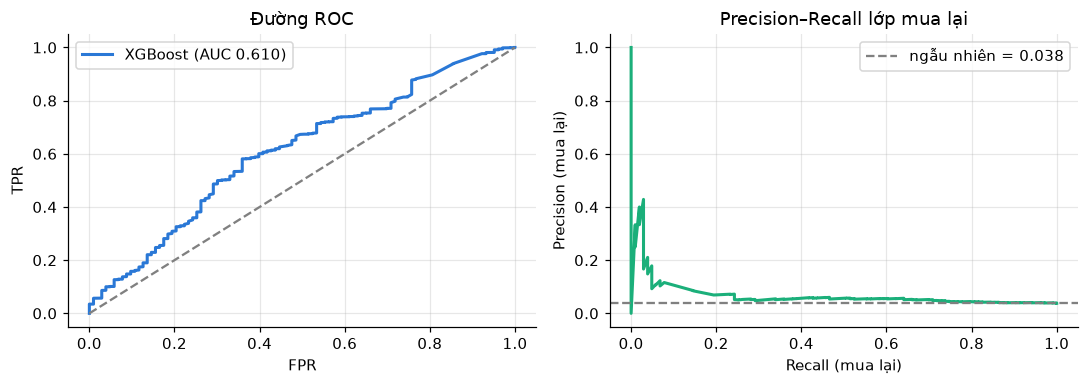

In [4]:
fpr, tpr, _ = roc_curve(y, p)
prec, rec, _ = precision_recall_curve(1 - y, 1 - p)  # lớp thiểu số = mua lại
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(fpr, tpr, color=C[0], lw=2, label=f"{m['best_model']} (AUC {roc_auc_score(y, p):.3f})"); axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("Đường ROC"); axes[0].legend()
axes[1].plot(rec, prec, color=C[2], lw=2); axes[1].axhline((1 - y).mean(), ls="--", color="gray", label=f"ngẫu nhiên = {(1 - y).mean():.3f}")
axes[1].set_xlabel("Recall (mua lại)"); axes[1].set_ylabel("Precision (mua lại)"); axes[1].set_title("Precision–Recall lớp mua lại"); axes[1].legend()
plt.tight_layout()

## 3. Chọn ngưỡng quyết định
Xác suất chưa hiệu chỉnh (do trọng số lớp), nên ngưỡng 0,5 không phải là tối ưu cho mọi mục tiêu. Bảng dưới cho thấy đánh đổi khi thay đổi ngưỡng.

In [5]:
rows = []
for t in np.arange(0.3, 0.81, 0.05):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    rows.append({"ngưỡng": round(t, 2), "% dự đoán churn": pred.mean(), "recall churn": tp / (tp + fn),
                 "recall mua lại": tn / (tn + fp), "balanced acc": (tp / (tp + fn) + tn / (tn + fp)) / 2})
pd.DataFrame(rows).set_index("ngưỡng").round(3)

,% dự đoán churn,recall churn,recall mua lại,balanced acc
ngưỡng,,,,
0.30,0.984,0.985,0.049,0.517
0.35,0.848,0.852,0.243,0.547
0.40,0.765,0.769,0.340,0.554
0.45,0.727,0.733,0.427,0.580
0.50,0.670,0.676,0.476,0.576
0.55,0.582,0.589,0.602,0.596
0.60,0.436,0.443,0.718,0.581
0.65,0.263,0.266,0.825,0.546
0.70,0.104,0.105,0.942,0.524


## 4. Giải thích mô hình bằng SHAP

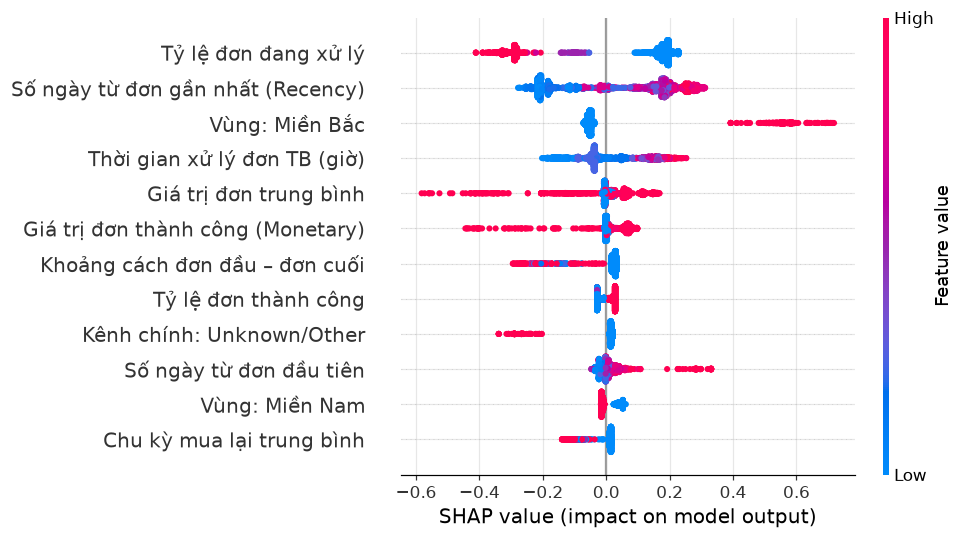

In [6]:
import shap
from backend.ml.explain import make_explainer, shap_matrix
explainer = make_explainer(model)
Xt = data["X_test"][features]
sv = shap_matrix(explainer, Xt)
shap.summary_plot(sv, Xt.rename(columns=fe.FEATURE_LABELS), max_display=12, show=False, plot_size=(9, 5))

Ghi chú: pipeline tính SHAP toàn cục trên **mẫu ngẫu nhiên 800 khách** của tập kiểm tra (`SHAP_SAMPLE` trong `train_advanced.py`), còn notebook tính trên **toàn bộ** tập kiểm tra, nên giá trị mean|SHAP| lệch nhẹ so với `model_metrics.json`; thứ hạng các đặc trưng hàng đầu giữ nguyên.

In [7]:
imp = pd.DataFrame({"đặc trưng": [fe.FEATURE_LABELS.get(f, f) for f in features], "mean|SHAP|": np.abs(sv).mean(0),
                    "tương quan giá trị–SHAP": [np.corrcoef(Xt.iloc[:, j], sv[:, j])[0, 1] if Xt.iloc[:, j].std() > 0 else np.nan for j in range(len(features))]})
imp.sort_values("mean|SHAP|", ascending=False).head(12).round(4)

,đặc trưng,mean|SHAP|,tương quan giá trị–SHAP
14,Tỷ lệ đơn đang xử lý,0.2138,-0.9938
0,Số ngày từ đơn gần nhất (Recency),0.1792,0.8080
30,Vùng: Miền Bắc,0.1209,0.9955
15,Thời gian xử lý đơn TB (giờ),0.0876,0.6774
3,Giá trị đơn trung bình,0.0512,0.0945
2,Giá trị đơn thành công (Monetary),0.0393,0.2902
5,Khoảng cách đơn đầu – đơn cuối,0.0379,-0.6026
11,Tỷ lệ đơn thành công,0.0244,0.9546
28,Kênh chính: Unknown/Other,0.0237,-0.9940
4,Số ngày từ đơn đầu tiên,0.0221,0.6648


In [8]:
# Giải thích cục bộ cho 1 khách hàng có rủi ro cao nhất (mã đã che)
i = int(np.argmax(p))
print("Khách:", mask_customer_id(str(data["X_test"].index[i])), f"| P(churn) = {p[i]:.3f} | thực tế: {'churn' if y[i] else 'mua lại'}")
local = pd.DataFrame({"đặc trưng": [fe.FEATURE_LABELS.get(f, f) for f in features], "giá trị": Xt.iloc[i].values, "SHAP": sv[i]})
local.reindex(local["SHAP"].abs().sort_values(ascending=False).index).head(6).round(4)

Khách: KH_0358***732 | P(churn) = 0.849 | thực tế: churn


,đặc trưng,giá trị,SHAP
27,Kênh chính: TikTok Shop,1.0000,0.8711
0,Số ngày từ đơn gần nhất (Recency),15.0842,0.2049
14,Tỷ lệ đơn đang xử lý,0.0000,0.1967
15,Thời gian xử lý đơn TB (giờ),210.5856,0.1510
3,Giá trị đơn trung bình,12.8662,0.1467
2,Giá trị đơn thành công (Monetary),12.8662,0.0950
